In [1]:
!pip install -q numpy pandas scipy matplotlib

# MIE1624 Assignment 1 — Simplified version
**Peinado · 1012953314**

Goal: (1) explore the survey, (2) compare **Remote vs Hybrid** salaries, (3) compare salaries of
**Bachelor's / Master's / Professional** degrees in the US and Canada.

All salaries are yearly, in USD. All Q2 differences are **Remote − Hybrid**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

SALARY = 'ConvertedCompYearly'
B = 10_000                        # bootstrap replications
ALPHA = 0.05                      # significance level
rng = np.random.default_rng(42)   # fixed seed -> same results every run

# The assignment reads the CSV from the notebook folder; fall back to the repo's data folder.
path = 'clean_stackoverflow_data.csv'
if not Path(path).exists():
    path = '../data/raw_data/clean_stackoverflow_data.csv'
df = pd.read_csv(path)
print('Raw data:', df.shape)

# Same study population as the submitted notebook: drop retired people and ages above 80
# (missing ages are kept because they do not violate the rule).
df = df[(df['DevType'] != 'Retired') & ~(df['Age'] > 80)]
print('After selection:', df.shape)

Raw data: (20407, 168)
After selection: (20312, 168)


### One helper for all bootstraps
Bootstrap = pretend the sample *is* the population. Draw $n$ values **with replacement**
from the group (same size as the group, as the assignment asks), compute the statistic,
repeat $B=10{,}000$ times. The spread of those $B$ values approximates the sampling
uncertainty of the statistic.

In [3]:
def bootstrap(x, stat=np.mean):
    """Return B bootstrap values of `stat`, each from a resample of x of size len(x)."""
    return np.array([stat(rng.choice(x, size=len(x), replace=True)) for _ in range(B)])

# Q1. Exploratory data analysis
## 1.1 Average job satisfaction by job title
`JobSat` is a 0–10 scale. One answer is **60**, which is impossible, so we drop it (only here).

JobSat values outside 0-10: 1


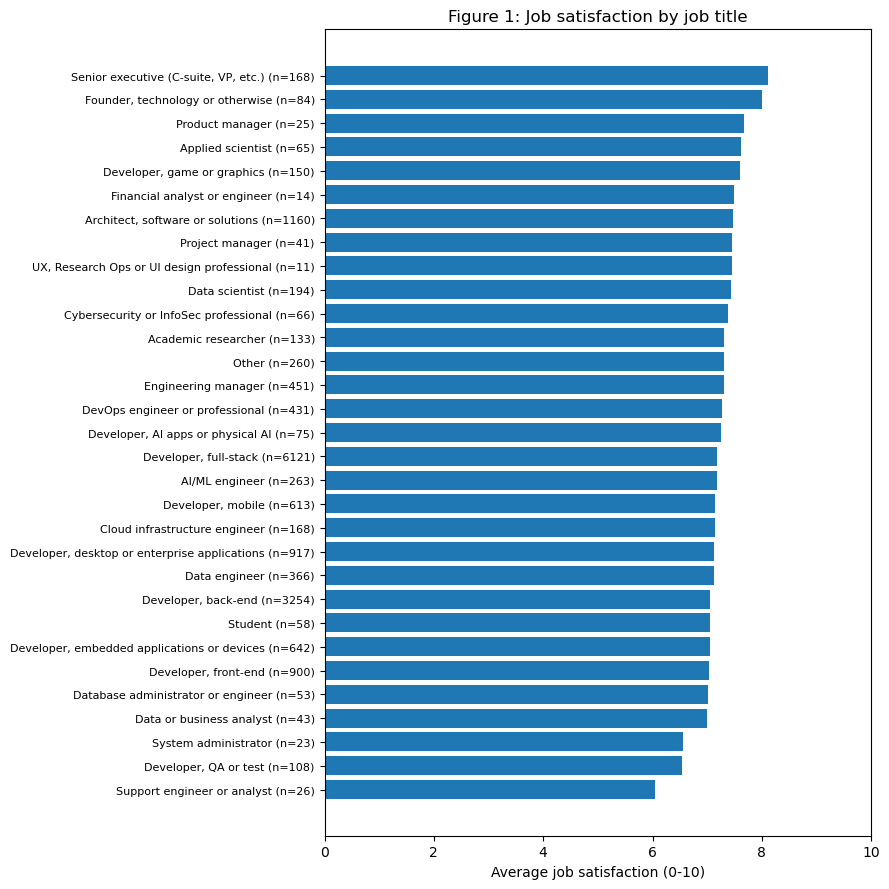

                                      mean  count
DevType                                          
Product manager                       7.68     25
Founder, technology or otherwise      8.01     84
Senior executive (C-suite, VP, etc.)  8.12    168


In [4]:
print('JobSat values outside 0-10:', (df['JobSat'] > 10).sum())
sat = (df[df['JobSat'] <= 10]
       .groupby('DevType')['JobSat'].agg(['mean', 'count'])
       .sort_values('mean'))

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh([f'{t} (n={n})' for t, n in zip(sat.index, sat['count'])], sat['mean'])
ax.set(xlim=(0, 10), xlabel='Average job satisfaction (0-10)', title='Figure 1: Job satisfaction by job title')
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
print(sat.tail(3).round(2))

**Diagnosis:** management roles (executives, founders) are the most satisfied (≈8/10) and support/QA roles
the least (≈6–6.5), but several titles have very few answers (n < 30), so their positions are unreliable;
one impossible rating of 60 was removed.

## 1.2 Mean salary by job title

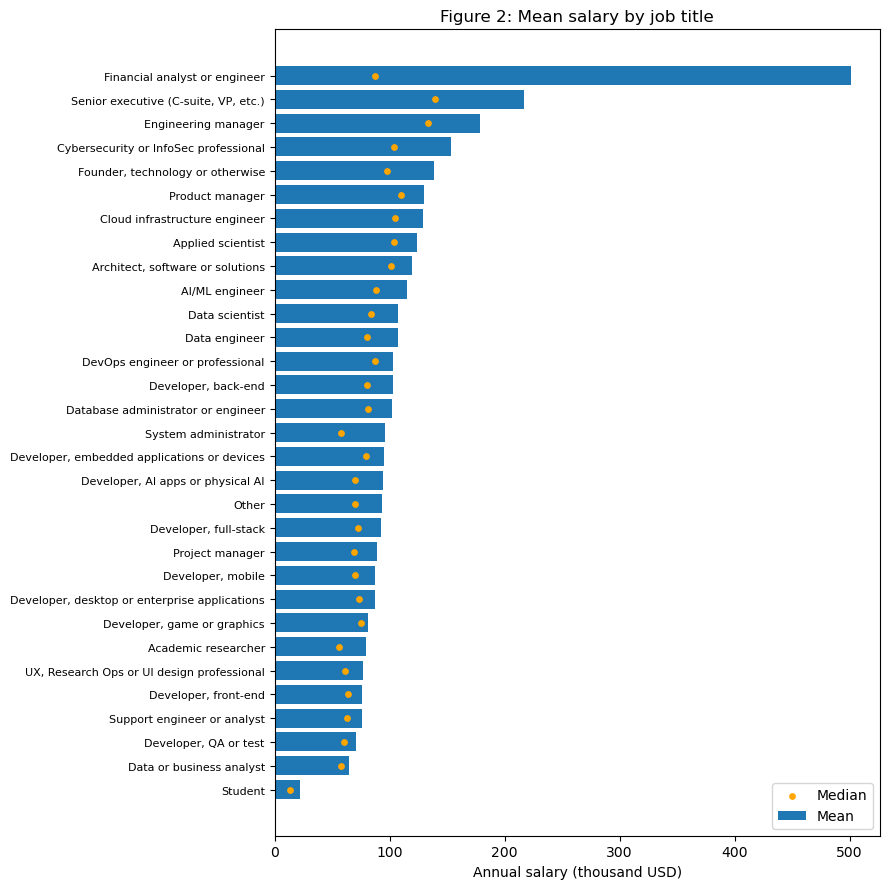

                                          mean    median  count
DevType                                                        
Engineering manager                   178839.0  133417.0    658
Senior executive (C-suite, VP, etc.)  216622.0  139218.0    272
Financial analyst or engineer         501248.0   87248.0     46


In [5]:
pay = df.groupby('DevType')[SALARY].agg(['mean', 'median', 'count']).sort_values('mean')

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(pay.index, pay['mean'] / 1000, label='Mean')
ax.scatter(pay['median'] / 1000, pay.index, color='orange', s=15, label='Median', zorder=3)
ax.set(xlabel='Annual salary (thousand USD)', title='Figure 2: Mean salary by job title')
ax.tick_params(axis='y', labelsize=8); ax.legend()
plt.tight_layout(); plt.show()
print(pay.tail(3).round(0))

**Diagnosis:** "Financial analyst or engineer" has the top mean (~\$500k) but a median of only ~\$87k with n=46,
so one or two extreme salaries create that bar; in general mean > median, i.e. salaries are **right-skewed**.

## 1.3 Annual salary vs. age

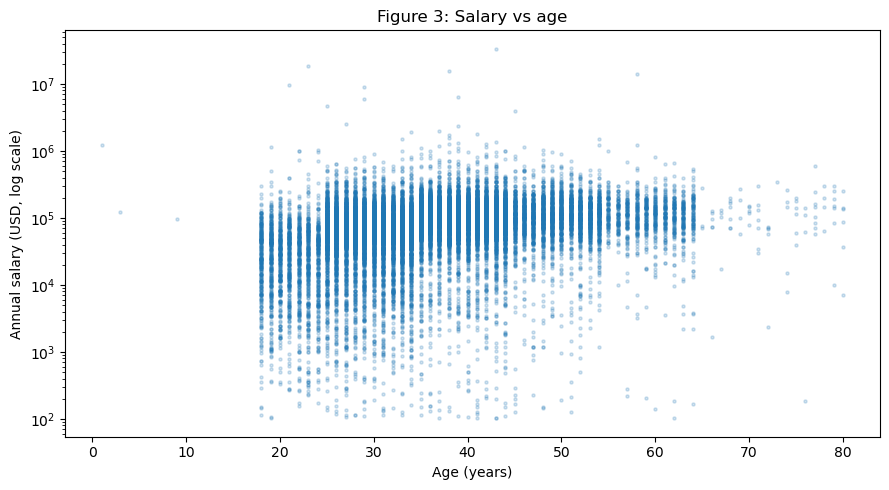

Ages below 15: 3 | min salary: 102 | max salary: 33552715


In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df['Age'], df[SALARY], s=5, alpha=0.2)
ax.set(yscale='log', xlabel='Age (years)', ylabel='Annual salary (USD, log scale)',
       title='Figure 3: Salary vs age')
plt.tight_layout(); plt.show()
print('Ages below 15:', (df['Age'] < 15).sum(), '| min salary:', df[SALARY].min(), '| max salary:', df[SALARY].max())

**Diagnosis:** salary tends to rise with age until ~50 and then flattens, but the spread at every age is huge;
ages below 15 and salaries of ~\$100 or ~\$33M are anomalies (data-entry or currency errors).

# Q2. Remote vs Hybrid salaries
## 2(a) Descriptive statistics and outliers
Outlier rule (Tukey): a value is an outlier if it is outside $[Q_1-1.5\,IQR,\;Q_3+1.5\,IQR]$, with $IQR=Q_3-Q_1$.

In [7]:
remote = df.loc[df['RemoteWork'] == 'Remote', SALARY].to_numpy()
hybrid = df.loc[df['RemoteWork'] == 'Hybrid', SALARY].to_numpy()

def iqr_mask(x):
    """True for values inside the Tukey fences (i.e. NOT outliers)."""
    q1, q3 = np.percentile(x, [25, 75])
    return (x >= q1 - 1.5 * (q3 - q1)) & (x <= q3 + 1.5 * (q3 - q1))

desc = pd.DataFrame({'Remote': pd.Series(remote).describe(), 'Hybrid': pd.Series(hybrid).describe()})
desc.loc['skewness'] = [stats.skew(remote), stats.skew(hybrid)]
desc.loc['IQR outliers'] = [(~iqr_mask(remote)).sum(), (~iqr_mask(hybrid)).sum()]
display(desc.round(1))

print('Mean difference, all data      :', round(remote.mean() - hybrid.mean()))
print('Mean difference, outliers removed:', round(remote[iqr_mask(remote)].mean() - hybrid[iqr_mask(hybrid)].mean()))

,Remote,Hybrid
count,6888.0,7776.0
mean,118666.9,101423.0
std,444251.0,346625.9
min,102.0,104.0
25%,47566.0,47492.2
50%,90491.0,77730.0
75%,150000.0,116015.0
max,33552715.0,18387548.0
skewness,63.9,41.2
IQR outliers,204.0,400.0


Mean difference, all data      : 17244
Mean difference, outliers removed: 18705


**Decision: keep the outliers.** High salaries are real for some developers (e.g. US senior roles);
deleting 3–5% of people would change the question to "salary of typical earners". Instead we remember
that the mean is sensitive to them, and in 2(f) we also compare **medians**, which are robust.

## 2(b) Two-sample t-test (manual, then SciPy)
$H_0:\mu_R=\mu_H$ vs $H_1:\mu_R\neq\mu_H$.

| step | formula |
|---|---|
| means | $\bar x_g=\frac{1}{n_g}\sum x_i$ |
| variances | $s_g^2=\frac{\sum (x_i-\bar x_g)^2}{n_g-1}$ |
| pooled SD | $s_p=\sqrt{\frac{(n_R-1)s_R^2+(n_H-1)s_H^2}{n_R+n_H-2}}$ |
| standard error | $SE=s_p\sqrt{\frac1{n_R}+\frac1{n_H}}$ |
| t statistic | $t=\frac{\bar x_R-\bar x_H}{SE}$, with $df=n_R+n_H-2$ |
| p-value | $p=2\,P(T_{df}\ge |t|)$ |

**Intuition:** $t$ = "how many standard errors apart are the two means?"

In [8]:
n1, n2 = len(remote), len(hybrid)
m1, m2 = remote.sum() / n1, hybrid.sum() / n2
v1 = ((remote - m1) ** 2).sum() / (n1 - 1)
v2 = ((hybrid - m2) ** 2).sum() / (n2 - 1)
sp = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
se = sp * np.sqrt(1 / n1 + 1 / n2)
t_obs = (m1 - m2) / se
dof = n1 + n2 - 2
p_obs = 2 * stats.t.sf(abs(t_obs), dof)

print(f'n: {n1} remote, {n2} hybrid')
print(f'means: {m1:,.0f} vs {m2:,.0f}  -> difference {m1 - m2:,.0f}')
print(f'variances: {v1:.3e} vs {v2:.3e}')
print(f'pooled SD = {sp:,.0f}   SE = {se:,.0f}')
print(f'MANUAL : t = {t_obs:.4f}, df = {dof}, p = {p_obs:.4f}')

scipy_t = stats.ttest_ind(remote, hybrid, equal_var=True)
print(f'SCIPY  : t = {scipy_t.statistic:.4f}, p = {scipy_t.pvalue:.4f}   (identical)')

# Are the t-test assumptions OK?
print(f'Levene (equal variances) p = {stats.levene(remote, hybrid).pvalue:.2e}')
print(f'Skewness: remote {stats.skew(remote):.1f}, hybrid {stats.skew(hybrid):.1f} (normal data = 0)')
print(f'Welch t-test (no equal-variance assumption): p = {stats.ttest_ind(remote, hybrid, equal_var=False).pvalue:.4f}')

n: 6888 remote, 7776 hybrid
means: 118,667 vs 101,423  -> difference 17,244
variances: 1.974e+11 vs 1.201e+11
pooled SD = 395,495   SE = 6,544
MANUAL : t = 2.6351, df = 14662, p = 0.0084
SCIPY  : t = 2.6351, p = 0.0084   (identical)
Levene (equal variances) p = 1.44e-02
Skewness: remote 63.9, hybrid 41.2 (normal data = 0)
Welch t-test (no equal-variance assumption): p = 0.0094


**Result:** manual and SciPy match exactly. $p\approx0.008<0.05$ → reject $H_0$: if the true means were
equal, a gap this large would appear less than 1% of the time.

**Why the t-test is not really suitable here:**
1. Salaries are **not normal** — extremely right-skewed (skewness ≫ 0) with huge outliers.
2. Levene's test rejects **equal variances**, which the pooled t-test assumes.

The large $n$ helps (Central Limit Theorem), but outliers still distort the mean and SD. That is the
reason for bootstrapping next (no normality assumption) and the median test in 2(f).

## 2(c) Bootstrap
For each replication $b=1..10{,}000$: resample each group at its own size, compute
$\bar x_R^{*b}$, $\bar x_H^{*b}$ and the difference $\Delta^{*b}=\bar x_R^{*b}-\bar x_H^{*b}$.

**Standardization** — this is the part that was graded wrong. A t statistic is
"(estimate − value under $H_0$) / standard error". Do the same with each bootstrap difference:
$$z^{*b}=\frac{\Delta^{*b}-0}{SE_{boot}},\qquad SE_{boot}=\mathrm{SD}(\Delta^{*1},\dots,\Delta^{*B}).$$
Because $\Delta^{*b}$ is centred on the observed gap, the **mean of $z^*$ ≈ observed gap / SE ≈ the t statistic from 2(b).**

In [9]:
boot_remote = bootstrap(remote)          # 10,000 bootstrap means
boot_hybrid = bootstrap(hybrid)
boot_diff = boot_remote - boot_hybrid    # 10,000 bootstrap differences
se_boot = boot_diff.std(ddof=1)          # bootstrap standard error of the difference
boot_z = boot_diff / se_boot             # standardized (NOT centred) differences

print(f'Bootstrap SE of difference: {se_boot:,.0f}   (formula SE from 2b: {se:,.0f})')
print(f'Mean of standardized distribution: {boot_z.mean():.3f}')
print(f't statistic from 2(b):              {t_obs:.3f}   -> approximately equal')

Bootstrap SE of difference: 6,653   (formula SE from 2b: 6,544)
Mean of standardized distribution: 2.601
t statistic from 2(b):              2.635   -> approximately equal


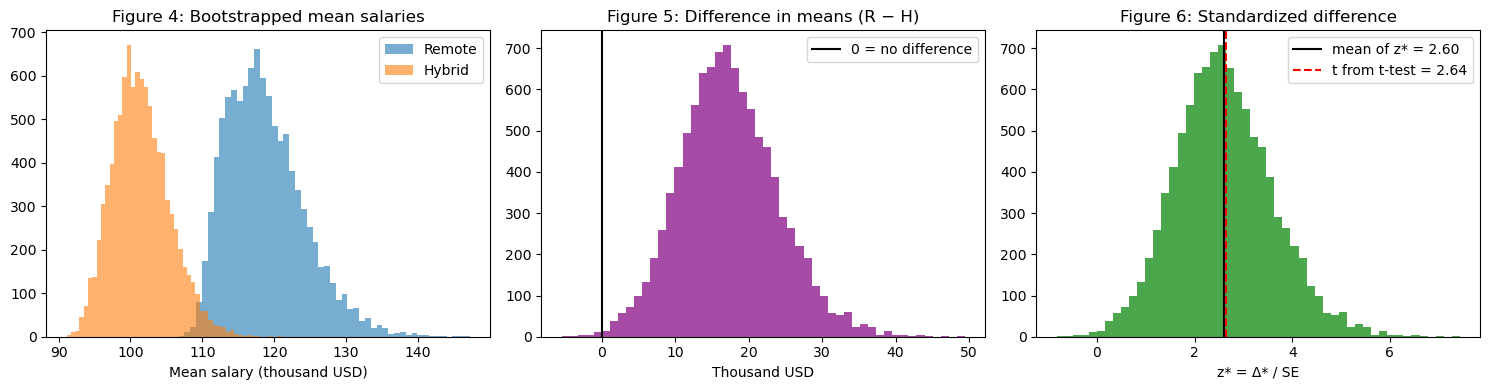

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
ax.hist(boot_remote / 1000, bins=50, alpha=0.6, label='Remote')
ax.hist(boot_hybrid / 1000, bins=50, alpha=0.6, label='Hybrid')
ax.set(title='Figure 4: Bootstrapped mean salaries', xlabel='Mean salary (thousand USD)'); ax.legend()

ax = axes[1]
ax.hist(boot_diff / 1000, bins=50, color='purple', alpha=0.7)
ax.axvline(0, color='k', label='0 = no difference')
ax.set(title='Figure 5: Difference in means (R − H)', xlabel='Thousand USD'); ax.legend()

ax = axes[2]
ax.hist(boot_z, bins=50, color='green', alpha=0.7)
ax.axvline(boot_z.mean(), color='k', label=f'mean of z* = {boot_z.mean():.2f}')
ax.axvline(t_obs, color='r', ls='--', label=f't from t-test = {t_obs:.2f}')
ax.set(title='Figure 6: Standardized difference', xlabel='z* = Δ* / SE'); ax.legend()
plt.tight_layout(); plt.show()

**Reading the figures**
- Fig 4: the remote curve sits to the right of the hybrid curve (remote earns more on average). Remote is
  a bit wider: smaller group and more spread.
- Fig 5: the differences are centred near the observed gap and almost none of them reach 0.
- Fig 6: same shape as Fig 5, but in "standard-error units". Its **mean ≈ t statistic** of 2(b).

### What was wrong in the original notebook
The original code did `standardize(x) = (x - mean(x)) / sd(x)`. Subtracting the mean **forces the
mean to be 0** (and SD 1) by construction, so the plot just looks like N(0,1) and loses the link to the
t-test. That is a z-score / "normalization" of the shape, not standardization against $H_0$.
The rubric expects you to divide by the standard error **without** removing the gap, and to **state** that
the mean of that distribution ≈ the t statistic. Same mistake in Q3(c). Side by side:

In [11]:
old_z = (boot_diff - boot_diff.mean()) / boot_diff.std(ddof=1)   # original (wrong for this purpose)
print(f'Original method : mean = {old_z.mean():.3f}  (always 0, tells us nothing)')
print(f'Correct method  : mean = {boot_z.mean():.3f}  (~ t = {t_obs:.3f})')

Original method : mean = 0.000  (always 0, tells us nothing)
Correct method  : mean = 2.601  (~ t = 2.635)


## 2(d) t-test on the bootstrapped data
Run the same two-sample t-test, now on the two arrays of 10,000 bootstrap means.

In [12]:
boot_t = stats.ttest_ind(boot_remote, boot_hybrid, equal_var=True)
print(f'Bootstrap-data t-test: t = {boot_t.statistic:.1f}, p = {boot_t.pvalue:.1e}')
print(f'Original t-test 2(b):  t = {t_obs:.2f},  p = {p_obs:.4f}')

# Direct bootstrap evidence: how often is the difference on the other side of 0?
p_boot = 2 * min((boot_diff <= 0).mean(), (boot_diff >= 0).mean())
print(f'Two-sided bootstrap p-value (share of differences crossing 0) = {p_boot:.4f}')

Bootstrap-data t-test: t = 259.1, p = 0.0e+00
Original t-test 2(b):  t = 2.64,  p = 0.0084
Two-sided bootstrap p-value (share of differences crossing 0) = 0.0050


**Both reject $H_0$ at 0.05 → same conclusion as 2(b): remote workers earn more on average.**

Caveat: the t-test on bootstrap means gives a huge $t$ and tiny $p$ only because it treats the
10,000 replications as 10,000 people. Raising $B$ would shrink $p$ further without new data. The
"share of differences crossing 0" p-value is the more honest bootstrap number, and it is close to the 2(b) p-value.

## 2(e) 95% confidence intervals for $\mu_R-\mu_H$
- **Formula:** $(\bar x_R-\bar x_H)\pm t_{0.975,df}\cdot SE$
- **Bootstrap (percentile):** the 2.5th and 97.5th percentiles of the 10,000 differences.

In [13]:
t_crit = stats.t.ppf(0.975, dof)
ci_formula = (m1 - m2) - t_crit * se, (m1 - m2) + t_crit * se
ci_boot = np.percentile(boot_diff, [2.5, 97.5])
print(f'Formula CI  : [{ci_formula[0]:,.0f}, {ci_formula[1]:,.0f}]')
print(f'Bootstrap CI: [{ci_boot[0]:,.0f}, {ci_boot[1]:,.0f}]')

Formula CI  : [4,417, 30,071]
Bootstrap CI: [4,942, 31,218]


Both intervals exclude 0 → same conclusion (remote mean is higher). They are close but not identical:
the formula assumes a symmetric t shape and a pooled variance, while the bootstrap uses the real
(skewed) data, so its interval is slightly shifted. Random resampling also adds a little noise.

## 2(f) Medians: Mood's test vs bootstrap
**Mood's median test:** find the combined median, count how many people in each group are above / below it,
and run a chi-square test on that 2×2 table. If medians were equal, each group would be ~50/50.

**Bootstrap:** bootstrap the median of each group, take the differences, and compute the two-sided p-value
$p=2\min\big(P(\Delta^*_{med}\le0),\,P(\Delta^*_{med}\ge0)\big)$.

In [14]:
mood_stat, p_mood, grand_median, table = stats.median_test(remote, hybrid)
print(f'Medians: remote {np.median(remote):,.0f}, hybrid {np.median(hybrid):,.0f}, combined {grand_median:,.0f}')
print(pd.DataFrame(table, index=['above', 'at/below'], columns=['Remote', 'Hybrid']))
print(f"Mood's test: chi2 = {mood_stat:.1f}, p = {p_mood:.1e}")

boot_med_diff = bootstrap(remote, np.median) - bootstrap(hybrid, np.median)
p_boot_med = 2 * min((boot_med_diff <= 0).mean(), (boot_med_diff >= 0).mean())
print(f'Bootstrap median difference: mean {boot_med_diff.mean():,.0f}, '
      f'95% CI [{np.percentile(boot_med_diff, 2.5):,.0f}, {np.percentile(boot_med_diff, 97.5):,.0f}]')
print(f'Bootstrap two-sided p = {p_boot_med}  (0 means < 1/B = {1 / B})')

Medians: remote 90,491, hybrid 77,730, combined 81,870
          Remote  Hybrid
above       3755    3566
at/below    3133    4210
Mood's test: chi2 = 109.1, p = 1.5e-25
Bootstrap median difference: mean 13,138, 95% CI [10,000, 16,242]
Bootstrap two-sided p = 0.0  (0 means < 1/B = 0.0001)


**Both p-values are essentially 0 → the remote median is clearly higher.** They agree in the decision.
Numerically they can't match exactly: Mood's p (~1e-25) is far smaller than the smallest p 10,000 bootstrap
replications can show (1/10,000). The median gap (~\$12.8k) is smaller than the mean gap (~\$17k) but much
*more* significant: medians ignore the extreme salaries that inflate the variance in the t-test.

# Q3. Education level (US and Canada only)
## 3(a) Descriptive statistics and outliers

In [15]:
degrees = ["Bachelor's degree", "Master's degree", 'Professional degree']
na = df[df['Country'].isin(['United States of America', 'Canada']) & df['EdLevel'].isin(degrees)]
groups = {d: na.loc[na['EdLevel'] == d, SALARY].to_numpy() for d in degrees}

desc3 = pd.DataFrame({d: pd.Series(x).describe() for d, x in groups.items()})
desc3.loc['skewness'] = [stats.skew(x) for x in groups.values()]
desc3.loc['IQR outliers'] = [(~iqr_mask(x)).sum() for x in groups.values()]
display(desc3.round(1))

,Bachelor's degree,Master's degree,Professional degree
count,2954.0,1067.0,295.0
mean,161010.6,183133.1,199595.8
std,114048.1,162860.3,196280.6
min,126.0,125.0,185.0
25%,100000.0,112000.0,109438.0
50%,140000.0,160000.0,160000.0
75%,190000.0,216500.0,218500.0
max,1950000.0,3900000.0,2346000.0
skewness,4.8,12.1,5.9
IQR outliers,151.0,54.0,21.0


Same decision as Q2: **keep outliers** (high North-American salaries are plausible), but note that the
Professional group is small and has the largest spread, so its mean is the least stable.

## 3(b) One-way ANOVA
$H_0:\mu_B=\mu_M=\mu_P$ vs $H_1$: at least one mean differs.
$$F=\frac{\text{between-group variance}}{\text{within-group variance}}
=\frac{\sum_g n_g(\bar x_g-\bar x)^2/(k-1)}{\sum_g (n_g-1)s_g^2/(N-k)}$$

In [16]:
anova = stats.f_oneway(*groups.values())
print(f'ANOVA: F = {anova.statistic:.2f}, p = {anova.pvalue:.2e}')
print(f'Levene (equal variances) p = {stats.levene(*groups.values()).pvalue:.2e}')
print('Group sizes:', [len(x) for x in groups.values()])
print('SDs:        ', [round(x.std(ddof=1)) for x in groups.values()])

ANOVA: F = 18.74, p = 7.91e-09
Levene (equal variances) p = 1.63e-05
Group sizes: [2954, 1067, 295]
SDs:         [114048, 162860, 196281]


**Result:** $p<0.05$ → reject $H_0$; at least one degree group has a different mean salary
(ANOVA doesn't say which one).

**Why ANOVA is not really suitable here:** ANOVA assumes (1) normal data in each group and (2) equal variances.
Salaries are strongly right-skewed, Levene rejects equal variances, and the group sizes are very unequal
(the small Professional group has the largest SD) — the worst case for ANOVA. So the p-value is approximate;
bootstrapping (3c–d) gives a check without those assumptions.

## 3(c) Bootstrap (three groups, three pairs)
Same recipe as 2(c), for each degree. Pairwise differences: B−M, B−P, M−P.
Standardize each pair the same (correct) way: $z^*=\Delta^*/SE_{boot}$. Its mean ≈ the t statistic of a
two-sample t-test between those two groups.

Here we compare with **Welch's** t: the bootstrap resamples each group separately, so its SE equals the
unpooled SE $\sqrt{s_a^2/n_a+s_b^2/n_b}$. With very unequal sizes and variances (Q3) the pooled t would not match;
in Q2 both versions were almost identical.

In [17]:
boot3 = {d: bootstrap(x) for d, x in groups.items()}
B_, M_, P_ = degrees
pairs = [(B_, M_), (B_, P_), (M_, P_)]
short = {B_: 'Bachelor', M_: 'Master', P_: 'Professional'}

rows = []
for a, b in pairs:
    diff = boot3[a] - boot3[b]
    z = diff / diff.std(ddof=1)
    rows.append({'pair': f'{short[a]} − {short[b]}',
                 'observed diff': groups[a].mean() - groups[b].mean(),
                 'bootstrap SE': diff.std(ddof=1),
                 'mean of z*': z.mean(),
                 'Welch t': stats.ttest_ind(groups[a], groups[b], equal_var=False).statistic})
display(pd.DataFrame(rows).set_index('pair').round(2))

,observed diff,bootstrap SE,mean of z*,Welch t
pair,,,,
Bachelor − Master,-22122.51,5423.17,-4.08,-4.09
Bachelor − Professional,-38585.18,11666.70,-3.31,-3.32
Master − Professional,-16462.67,12541.79,-1.32,-1.32


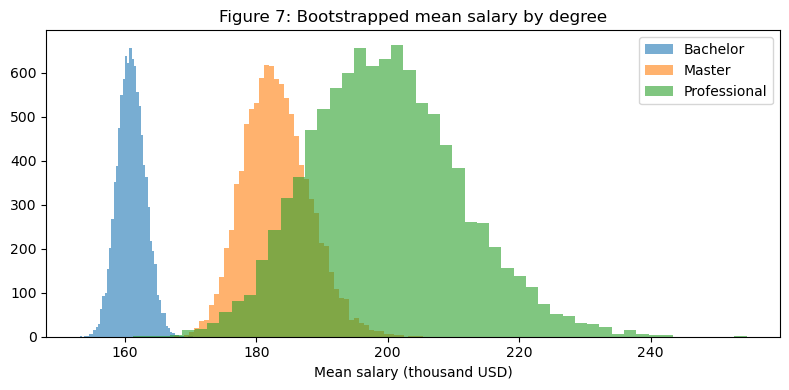

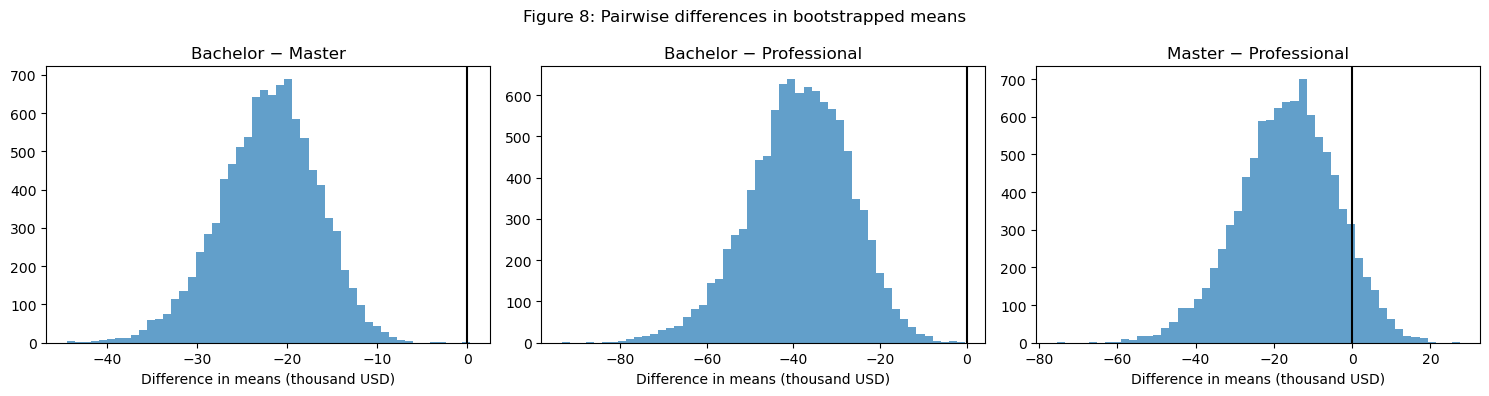

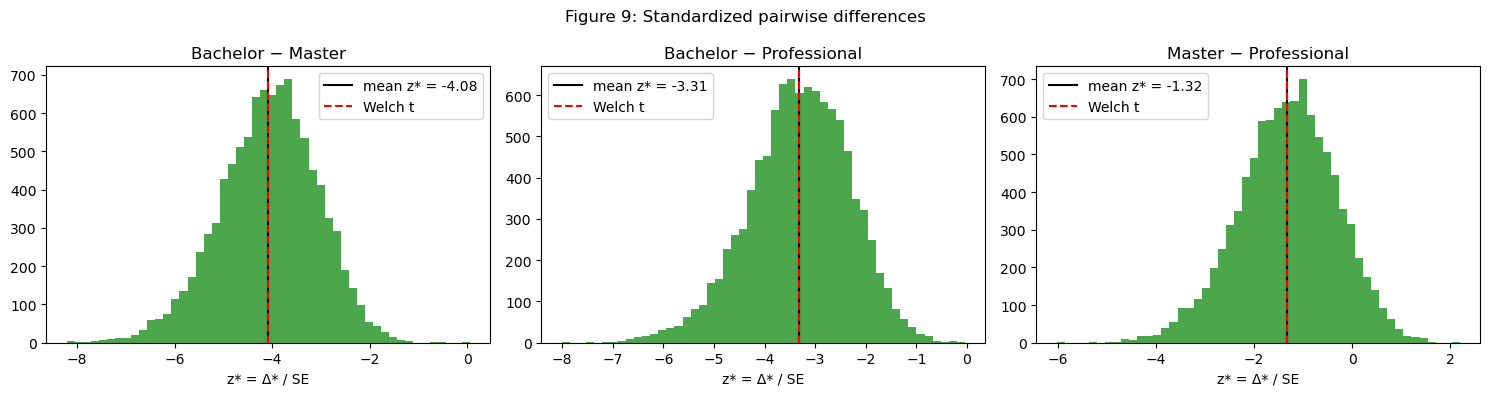

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
for d in degrees:
    ax.hist(boot3[d] / 1000, bins=50, alpha=0.6, label=short[d])
ax.set(title='Figure 7: Bootstrapped mean salary by degree', xlabel='Mean salary (thousand USD)'); ax.legend()
plt.tight_layout(); plt.show()

fig8, ax8 = plt.subplots(1, 3, figsize=(15, 4))
fig9, ax9 = plt.subplots(1, 3, figsize=(15, 4))
for i, (a, b) in enumerate(pairs):
    diff = boot3[a] - boot3[b]
    z = diff / diff.std(ddof=1)
    name = f'{short[a]} − {short[b]}'
    ax8[i].hist(diff / 1000, bins=50, alpha=0.7)
    ax8[i].axvline(0, color='k')
    ax8[i].set(title=name, xlabel='Difference in means (thousand USD)')
    ax9[i].hist(z, bins=50, alpha=0.7, color='green')
    ax9[i].axvline(z.mean(), color='k', label=f'mean z* = {z.mean():.2f}')
    ax9[i].axvline(stats.ttest_ind(groups[a], groups[b], equal_var=False).statistic, color='r', ls='--', label='Welch t')
    ax9[i].set(title=name, xlabel='z* = Δ* / SE'); ax9[i].legend()
fig8.suptitle('Figure 8: Pairwise differences in bootstrapped means'); fig8.tight_layout()
fig9.suptitle('Figure 9: Standardized pairwise differences'); fig9.tight_layout()
plt.show()

**Reading the figures**
- Fig 7: Bachelor's is the narrowest (largest group); Professional is the widest (small group, big spread).
- Fig 8: Bachelor−Master and Bachelor−Professional sit well below 0 (Bachelor's earn less);
  Master−Professional overlaps 0 (no clear difference).
- Fig 9: each mean z* ≈ the Welch t for that pair (table above). |z*| > ~2 ⇒ significant at 0.05 for that pair:
  true for the two Bachelor pairs (≈ −4.1, −3.3), not for Master−Professional (≈ −1.3).

## 3(d) ANOVA on the bootstrapped data

In [19]:
boot_anova = stats.f_oneway(*boot3.values())
print(f'Bootstrap-data ANOVA: F = {boot_anova.statistic:,.0f}, p = {boot_anova.pvalue:.1e}')
print(f'Original ANOVA 3(b):  F = {anova.statistic:.2f},  p = {anova.pvalue:.2e}')

Bootstrap-data ANOVA: F = 69,953, p = 0.0e+00
Original ANOVA 3(b):  F = 18.74,  p = 7.91e-09


Both reject $H_0$ → same conclusion as 3(b): mean salary differs by degree. As in 2(d), the bootstrap
F is enormous only because 10,000 replications are treated as observations; the sign of the conclusion,
not the size of F, is what matters.

# Summary
| Question | Result |
|---|---|
| Q2 means | Remote earns more than Hybrid; t-test, bootstrap and both CIs agree (gap ≠ 0). |
| Q2 medians | Remote median clearly higher (Mood and bootstrap agree). |
| Q2(c) fix | Standardize with $z^*=\Delta^*/SE$ (no centring) → mean of $z^*$ ≈ t statistic. |
| Q3 | Mean salary differs across degrees (ANOVA and bootstrap ANOVA agree), but ANOVA assumptions are violated. |

These are associations, not causes: country, job title and experience also differ between groups.